In [18]:
from pathlib import Path

import planetary_computer as pc
import pystac_client
import rasterio
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window

In [19]:
import logging

logging.basicConfig(level=logging.DEBUG, format="%(name)s %(message)s")
logging.getLogger("rasterio._env").setLevel(logging.DEBUG)

In [20]:
cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
longitude, latitude = -73.9857, 40.7484
item = max(
    cat.search(
        collections=["naip"], intersects={"type": "Point", "coordinates": [longitude, latitude]}, datetime="2018/2024"
    ).item_collection(),
    key=lambda i: i.properties["naip:year"],
)
print(item.id, item.properties["gsd"], item.properties["proj:shape"])

env = rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_MULTIPLEX="YES",
    GDAL_HTTP_VERSION="2",
    VSI_CACHE="TRUE",
    VSI_CACHE_SIZE=64000000,
    CPL_DEBUG="ON",
)

with env, rasterio.open(item.assets["image"].href) as src:
    (x,), (y,) = warp_transform("EPSG:4326", src.crs, [longitude], [latitude])
    row, col = src.index(x, y)
    # half = 0.6 * 256
    window = Window(col - 256, row - 256, 512, 512)
    arr = src.read([1, 2, 3], window=window)
    t = src.window_transform(window)
    px = (x - t.c) / t.a
    py = (y - t.f) / t.e
    out = Path("data/spike")
    out.mkdir(parents=True, exist_ok=True)

    profile = {
        "driver": "GTiff",
        "width": 512,
        "height": 512,
        "count": 3,
        "dtype": arr.dtype,
        "crs": src.crs,
        "transform": t,
        "compress": "deflate",
        "tiled": True,
        "blockxsize": 256,
        "blockysize": 256,
    }
    with rasterio.open(out / f"{item.id}_512.tif", "w", **profile) as dst:
        dst.write(arr)
    print(px, py)

urllib3.util.retry Converted retries value: 5 -> Retry(total=5, connect=None, read=None, redirect=None, status=None)
urllib3.util.retry Converted retries value: 5 -> Retry(total=5, connect=None, read=None, redirect=None, status=None)
pystac_client.stac_api_io GET https://planetarycomputer.microsoft.com/api/stac/v1 Headers: {'User-Agent': 'python-requests/2.34.2', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive'}
urllib3.connectionpool Starting new HTTPS connection (1): planetarycomputer.microsoft.com:443
urllib3.connectionpool https://planetarycomputer.microsoft.com:443 "GET /api/stac/v1 HTTP/1.1" 200 650
pystac_client.stac_api_io GET https://planetarycomputer.microsoft.com/api/stac/v1/ Headers: {'User-Agent': 'python-requests/2.34.2', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive'}
urllib3.connectionpool https://planetarycomputer.microsoft.com:443 "GET /api/stac/v1/ HTTP/1.1" 200 650
pystac_client.stac_api_io POST https:/

ny_m_4007317_nw_18_060_20220719 0.6 [12330, 9600]


rasterio._err VSICURL: Download completed
rasterio.env Entering env context: <rasterio.env.Env object at 0x11ffad610>
rasterio.env Got a copy of environment <rasterio._env.GDALEnv object at 0x11ffb40d0> options
rasterio.env Entered env context: <rasterio.env.Env object at 0x11ffad610>
rasterio._env CPLE_None in GDAL: GDALDriver::Create(GTiff,data/spike/ny_m_4007317_nw_18_060_20220719_512.tif,512,512,3,Byte,0x9ad4285a0)
rasterio._base Nodata success: 0, Nodata value: 0.000000
rasterio._base Nodata success: 0, Nodata value: 0.000000
rasterio._base Nodata success: 0, Nodata value: 0.000000
rasterio.env Exiting env context: <rasterio.env.Env object at 0x11ffad610>
rasterio.env Cleared existing <rasterio._env.GDALEnv object at 0x11ffb40d0> options
rasterio._env Stopped GDALEnv <rasterio._env.GDALEnv object at 0x11ffb40d0>.
rasterio.env No GDAL environment exists
rasterio.env New GDAL environment <rasterio._env.GDALEnv object at 0x11fd49690> created
rasterio._env GDAL data found in package: 

256.3484806375345 256.25436460754526


In [12]:
import itertools
import time

import pandas as pd

STATES = [
    "al",
    "az",
    "ar",
    "ca",
    "co",
    "ct",
    "de",
    "fl",
    "ga",
    "id",
    "il",
    "in",
    "ia",
    "ks",
    "ky",
    "la",
    "me",
    "md",
    "ma",
    "mi",
    "mn",
    "ms",
    "mo",
    "mt",
    "ne",
    "nv",
    "nh",
    "nj",
    "nm",
    "ny",
    "nc",
    "nd",
    "oh",
    "ok",
    "or",
    "pa",
    "ri",
    "sc",
    "sd",
    "tn",
    "tx",
    "ut",
    "vt",
    "va",
    "wa",
    "wv",
    "wi",
    "wy",
]
YEARS = range(2018, 2026)

rows = []
for st, yr in itertools.product(STATES, YEARS):
    res = cat.search(
        collections=["naip"],
        query={"naip:state": {"eq": st}},
        datetime=f"{yr}-01-01/{yr}-12-31",
        max_items=1,
    ).item_collection()
    if res:
        it = res[0]
        rows.append({"state": st, "year": yr, "gsd": it.properties["gsd"], "id": it.id})
    time.sleep(1)

df = pd.DataFrame(rows)
print(df.pivot(index="state", columns="year", values="gsd").to_string())
print(df.groupby(["year", "gsd"]).size())

pystac_client.stac_api_io POST https://planetarycomputer.microsoft.com/api/stac/v1/search Headers: {'User-Agent': 'python-requests/2.34.2', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive', 'Content-Length': '121', 'Content-Type': 'application/json'} Payload: {"datetime": "2018-01-01T00:00:00Z/2018-12-31T23:59:59Z", "collections": ["naip"], "query": {"naip:state": {"eq": "al"}}}
urllib3.connectionpool https://planetarycomputer.microsoft.com:443 "POST /api/stac/v1/search HTTP/1.1" 200 287
pystac_client.stac_api_io POST https://planetarycomputer.microsoft.com/api/stac/v1/search Headers: {'User-Agent': 'python-requests/2.34.2', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive', 'Content-Length': '121', 'Content-Type': 'application/json'} Payload: {"datetime": "2019-01-01T00:00:00Z/2019-12-31T23:59:59Z", "collections": ["naip"], "query": {"naip:state": {"eq": "al"}}}
urllib3.connectionpool https://planetarycomputer.microsoft.com:

year   2018  2019  2020  2021  2022  2023
state                                    
al      NaN   0.6   NaN   0.3   NaN   0.6
ar      NaN   0.6   NaN   0.6   NaN   0.3
az      NaN   0.6   NaN   0.6   0.6   0.3
ca      0.6   0.6   0.6   NaN   0.3   NaN
co      NaN   0.6   NaN   0.6   NaN   0.3
ct      0.6   NaN   NaN   0.6   NaN   0.3
de      0.6   NaN   NaN   0.6   NaN   0.3
fl      NaN   0.6   NaN   0.6   0.6   0.3
ga      NaN   0.6   NaN   0.6   0.6   0.6
ia      NaN   0.6   NaN   0.6   NaN   0.3
id      NaN   0.6   NaN   0.6   NaN   0.6
il      NaN   0.6   NaN   0.6   NaN   0.3
in      0.6   NaN   0.6   NaN   0.6   NaN
ks      NaN   0.6   NaN   0.6   NaN   0.3
ky      0.6   NaN   0.6   NaN   0.6   NaN
la      NaN   0.6   NaN   0.3   0.3   0.3
ma      0.6   NaN   NaN   0.6   NaN   0.3
md      0.6   NaN   NaN   0.6   NaN   0.3
me      0.6   NaN   NaN   0.6   NaN   0.3
mi      0.6   NaN   0.6   NaN   0.6   NaN
mn      NaN   0.6   NaN   0.6   NaN   0.3
mo      0.6   NaN   0.6   NaN   0.

matplotlib matplotlib data path: /Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/matplotlib/mpl-data
matplotlib CONFIGDIR=/Users/phillip/.matplotlib
matplotlib interactive is False
matplotlib platform is darwin
matplotlib CACHEDIR=/Users/phillip/.matplotlib
matplotlib.font_manager Using fontManager instance from /Users/phillip/.matplotlib/fontlist-v3.11.0.json
rasterio.env Entering env context: <rasterio.env.Env object at 0x1214f8c80>
rasterio.env Starting outermost env
rasterio.env No GDAL environment exists
rasterio.env New GDAL environment <rasterio._env.GDALEnv object at 0x12121dcf0> created
rasterio._env GDAL data found in package: path='/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/gdal_data'.
rasterio._env PROJ data found in package: path='/Users/phillip/repositories/bachelor-thesis/.venv/lib/python3.12/site-packages/rasterio/proj_data'.
rasterio._env Started GDALEnv: self=<rasterio._env.GDALEnv object at 0

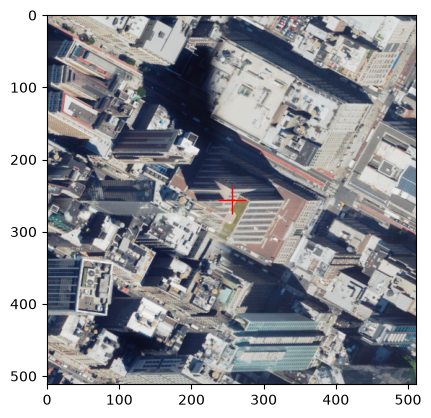

In [22]:
import matplotlib.pyplot as plt

with rasterio.open(
    "/Users/phillip/repositories/bachelor-thesis/data/spike/ny_m_4007317_nw_18_060_20220719_512.tif"
) as d:
    plt.figure()
    plt.imshow(d.read([1, 2, 3]).transpose(1, 2, 0))
    plt.plot(px, py, "r+", ms=20)  # pin